# 05 · EDA: look at the corpus before we index it

Phase 3 fetched **8,657** repositories and Phase 4 cleaned them down to **8,223** (`data/processed/corpus.parquet`). Before anyone builds an index, we look at what is actually in there.

**Rule for this notebook:** every chart ends with one sentence, *"This shows … so we will …"*. A chart that changes no decision doesn't belong in the report.

| # | Chart | Question | Decision it drives |
|---|---|---|---|
| 1 | README length | How much text do we have? | README cap; how much embeddings must help on short READMEs |
| 2 | Repositories per domain and framework | Is the corpus balanced? | Whether to collect more for weak slices |
| 3 | Stars | Is popularity skewed? | Log scaling in the final score |
| 4 | Top terms and Zipf | Which words are noise? | Extra stop words |
| 5 | Technologies per repository | Does the dictionary cover the corpus? | New aliases for `technologies.yaml` |
| 6 | Topics and contributors per repository | What can the graph rely on? | Which edges to use in Phase 12 |
| 7 | *Extra:* what is not a project | Are there repositories that would mislead the search? | A new cleaning rule |
| 8 | *Extra:* age, activity, language | What does a typical repository look like? | Context for the report |

In [1]:
%load_ext autoreload
%autoreload 2

import itertools
import json
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from nltk.corpus import stopwords

from discovery.collect.crawler import iter_jsonl
from discovery.config import BACKEND, PATHS, SEED, load_config, set_seed

set_seed()
cfg = load_config()
DOMAINS, FRAMEWORKS = cfg["collection"]["domains"], cfg["collection"]["frameworks"]
TARGET = cfg["collection"]["target_size"]
BLUE, ORANGE, GREY, GREEN = "#2a78d6", "#e0662f", "#9ca3af", "#1f9d74"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25,
                     "axes.axisbelow": True, "figure.dpi": 110})

corpus = pd.read_parquet(PATHS["processed"] / "corpus.parquet")
log = pd.read_csv(PATHS["processed"] / "cleaning_log.csv")
corpus["n_words"] = corpus["readme"].str.split().str.len()
corpus["owner"] = corpus["full_name"].str.split("/").str[0]
# which (domain, framework) slice picked each repository; "other" repositories carry their piece id instead
corpus["domains"] = corpus["selected_by"].map(lambda s: sorted({x.split("|")[0] for x in s}))
corpus["frameworks"] = corpus["selected_by"].map(lambda s: sorted({x.split("|")[1] for x in s if not x.startswith("other|")}))
corpus["is_other"] = corpus["domains"].map(lambda d: d == ["other"])
print(f"{len(corpus):,} repositories after cleaning ({log['before'].iloc[0]:,} fetched) | "
      f"{corpus['is_other'].sum():,} unrelated ('other') = {corpus['is_other'].mean():.0%} | target was {TARGET:,}")

8,223 repositories after cleaning (8,657 fetched) | 954 unrelated ('other') = 12% | target was 10,000


## 1. How much text do we have?

Word counts of the **cleaned** README (badges, code, link URLs and HTML already removed). The x-axis is on a log scale because the spread runs from 0 to several thousand words.

median 521 words | under 30 words: 378 (4.6%) | under 100: 13% | empty after cleaning: 104 (they rely on the description) | hit the 20,000-character cap: 1,296 (16%)


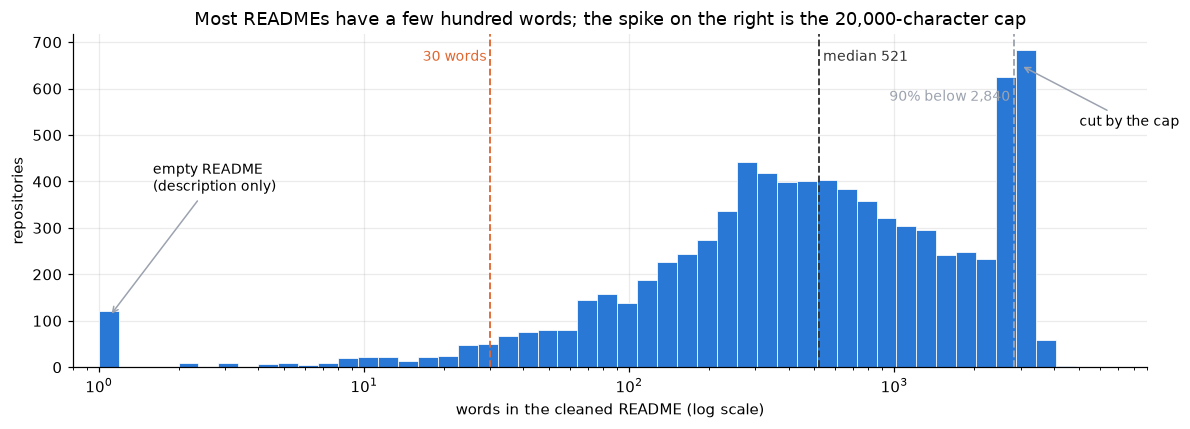

In [2]:
w = corpus["n_words"]
fig, ax = plt.subplots(figsize=(11, 4))
bins = np.logspace(0, np.log10(w.max() + 1), 50)
ax.hist(w.clip(lower=1), bins=bins, color=BLUE, edgecolor="white", linewidth=.5)
ax.set_xscale("log")
ax.set_xlim(.8, 9000)
for v, lab, col, ha in [(30, "30 words ", ORANGE, "right"), (w.median(), f" median {w.median():.0f}", "#333", "left"),
                        (w.quantile(.9), f"90% below {w.quantile(.9):,.0f} ", GREY, "right")]:
    ax.axvline(v, color=col, ls="--", lw=1.2)
    ax.text(v, ax.get_ylim()[1] * (.80 if ha == "right" and v > 100 else .92), lab, color=col, fontsize=9, ha=ha)
ax.annotate("empty README\n(description only)", (1.1, 110), (1.6, 380), fontsize=9, arrowprops={"arrowstyle": "->", "color": GREY})
ax.annotate("cut by the cap", (3000, 650), (5000, 520), fontsize=9, arrowprops={"arrowstyle": "->", "color": GREY})
ax.set_xlabel("words in the cleaned README (log scale)")
ax.set_ylabel("repositories")
ax.set_title("Most READMEs have a few hundred words; the spike on the right is the 20,000-character cap")
plt.tight_layout()

empty = (corpus["readme"].str.strip() == "").sum()
capped = int(log.loc[log["rule"].str.startswith("length cap"), "changed"].iloc[0])
print(f"median {w.median():.0f} words | under 30 words: {(w < 30).sum():,} ({(w < 30).mean():.1%}) | under 100: {(w < 100).mean():.0%} | "
      f"empty after cleaning: {empty} (they rely on the description) | hit the 20,000-character cap: {capped:,} ({capped / len(corpus):.0%})")

**This shows** a median of about 520 words, with **one in eight READMEs under 100 words** (104 are empty after cleaning and rely on the description) and **16% cut by the cap** (the spike on the right). **So we will** keep the 20,000-character cap (the cut part is mostly install steps and changelogs, and BM25's length normalisation would punish those READMEs anyway), and expect semantic search (Phase 10.1) to matter most on the short READMEs, where keyword methods have almost nothing to match.

## 2. Is the corpus balanced?

Each repository counts once for every domain (and framework) slice that **selected** it. Grey bar: what Phase 2 planned per slice group (Q = 84 per domain × framework slice, so up to 1,008 per domain or framework).

slices under 40 repositories: 22 of 144 → hospital management + nestjs (8), school management + nestjs (10), hospital management + nextjs (11), school management + fastapi (13), school management + flask (16), hospital management + rails (16), school management + nextjs (17), hospital management + fastapi (19), hospital management + flutter (22), library management + nestjs (25)


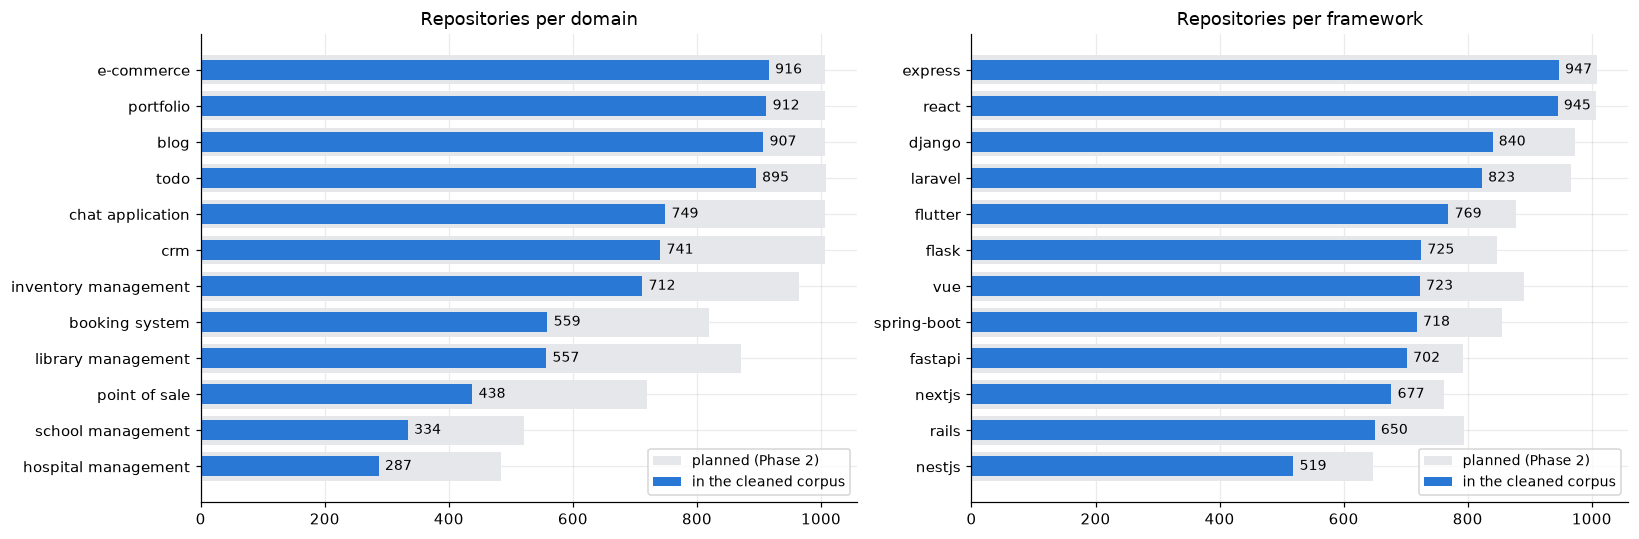

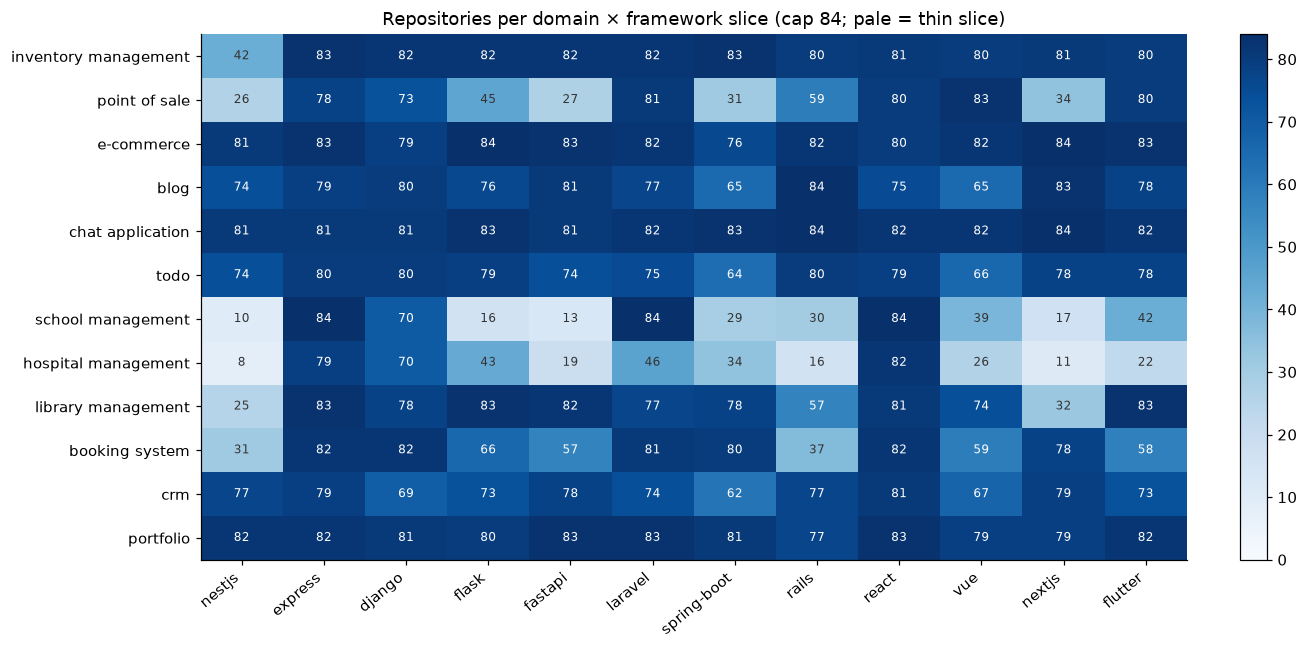

In [3]:
dom = Counter(d for ds in corpus["domains"] for d in ds)
fw = Counter(f for fs in corpus["frameworks"] for f in fs)
plan = pd.read_csv(BACKEND / "config" / "slices.csv")
plan_dom = plan.groupby("domain")["take"].sum()
plan_fw = plan.groupby("framework")["take"].sum()

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for a, got, planned, title in [(ax[0], dom, plan_dom, "per domain"), (ax[1], fw, plan_fw, "per framework")]:
    s = pd.Series(got).drop("other", errors="ignore").sort_values()
    a.barh(s.index, planned.reindex(s.index).fillna(0), color="#e5e7eb", label="planned (Phase 2)")
    a.barh(s.index, s.values, height=.55, color=BLUE, label="in the cleaned corpus")
    for i, v in enumerate(s.values):
        a.text(v + 10, i, f"{v:,}", va="center", fontsize=9)
    a.set_title(f"Repositories {title}")
    a.legend(loc="lower right", fontsize=9)
plt.tight_layout()

grid = pd.DataFrame(0, index=DOMAINS, columns=FRAMEWORKS)
for s in corpus["selected_by"]:
    for x in s:
        d, f = x.split("|")
        if d != "other":
            grid.loc[d, f] += 1
fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(grid, cmap="Blues", aspect="auto", vmin=0, vmax=84)
for (i, j), v in np.ndenumerate(grid.values):
    ax.text(j, i, v, ha="center", va="center", fontsize=8, color="white" if v > 55 else "#333")
ax.set_xticks(range(len(FRAMEWORKS)), FRAMEWORKS, rotation=40, ha="right")
ax.set_yticks(range(len(DOMAINS)), DOMAINS)
ax.grid(False)
ax.set_title("Repositories per domain × framework slice (cap 84; pale = thin slice)")
fig.colorbar(im, ax=ax, fraction=.03)
plt.tight_layout()
thin = grid.stack()[lambda s: s < 40].sort_values()
print(f"slices under 40 repositories: {len(thin)} of 144 → " + ", ".join(f"{d} + {f} ({v})" for (d, f), v in thin.head(10).items()))

**This shows** that the cap worked for the big domains (e-commerce, portfolio, blog, todo ≈ 900 each), but **point of sale (438), school management (334) and hospital management (287)** are small. That was already true in the Phase 2 plan (fewer such repositories exist), and it got worse because one repository often matches several slices: the 11,421 planned rows collapsed to **8,657 unique repositories** (one was found by 77 pieces), and cleaning left **8,223, not 10,000**. The heatmap shows **22 thin slices** (under 40), almost all of them school or hospital systems in NestJS, Next.js, FastAPI or Flask. **So we will** *not* re-crawl: every domain still has hundreds of repositories, enough to judge a top 10. In Phase 13 we keep school and hospital queries, but avoid asking for a thin pair (e.g. "hospital system in NestJS": only 8 candidates), and the report says the corpus is 8,223.

## 3. Is popularity skewed?

median 14 | mean 818 | max 541,198 | the top 1% of repositories hold 76% of all stars


,full_name,stars,language,description
7157,sindresorhus/awesome,541198,not specified,😎 Awesome lists about all kinds of interesting...
6586,public-apis/public-apis,500899,Python,A collective list of free APIs
3292,awesome-selfhosted/awesome-selfhosted,339616,not specified,A list of Free Software network services and w...
7847,vinta/awesome-python,336525,Python,"The definitive list that answers ""I want to do..."
6522,practical-tutorials/project-based-learning,290296,Python,Curated list of project-based tutorials
3271,avelino/awesome-go,195468,Go,"A curated list of awesome Go frameworks, libra..."
6016,msitarzewski/agency-agents,169841,Shell,A complete AI agency at your fingertips - From...
6775,ripienaar/free-for-dev,143402,HTML,"A list of SaaS, PaaS and IaaS offerings that h..."
2562,VoltAgent/awesome-design-md,128675,not specified,A collection of DESIGN.md files analysis by po...
6884,rust-lang/rust,122425,Rust,Empowering everyone to build reliable and effi...


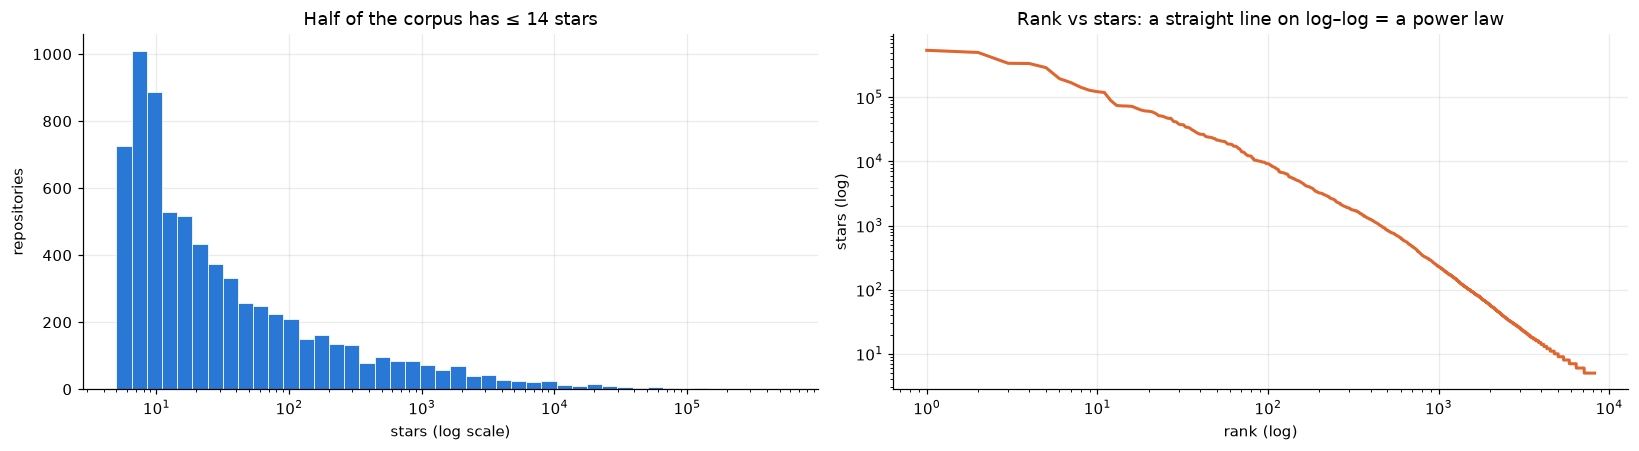

In [4]:
st = corpus["stars"]
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
ax[0].hist(st, bins=np.logspace(np.log10(5), np.log10(st.max()), 45), color=BLUE, edgecolor="white", linewidth=.5)
ax[0].set_xscale("log")
ax[0].set_xlabel("stars (log scale)")
ax[0].set_ylabel("repositories")
ax[0].set_title(f"Half of the corpus has ≤ {st.median():.0f} stars")
srt = np.sort(st.values)[::-1]
ax[1].loglog(np.arange(1, len(srt) + 1), srt, color=ORANGE, lw=2)
ax[1].set_xlabel("rank (log)")
ax[1].set_ylabel("stars (log)")
ax[1].set_title("Rank vs stars: a straight line on log–log = a power law")
plt.tight_layout()
top1 = srt[: len(srt) // 100].sum() / srt.sum()
print(f"median {st.median():.0f} | mean {st.mean():,.0f} | max {st.max():,} | the top 1% of repositories hold {top1:.0%} of all stars")
corpus.nlargest(10, "stars")[["full_name", "stars", "language", "description"]].assign(description=lambda d: d["description"].str[:70])

**This shows** a power law: the median repository has **14 stars** while **the top 1% hold 76% of all stars**, and **the 10 most-starred repositories are almost all link lists** ("awesome …", public-apis), not projects. **So we will** put popularity on a **log scale** in Phase 12 (`log1p(stars)`, then min–max), keep its weight small (0.2 of the final score), and deal with the link lists first (section 7), or they would win every query on popularity alone.

## 4. Which words are noise? Top terms and Zipf's law

A quick tokenizer here (lowercase, letters only, NLTK English stop words removed). The real tokenizer comes in Phase 6; this is only to see the vocabulary.

5,739,652 tokens | 167,548 distinct terms | 85,340 appear only once (51%)


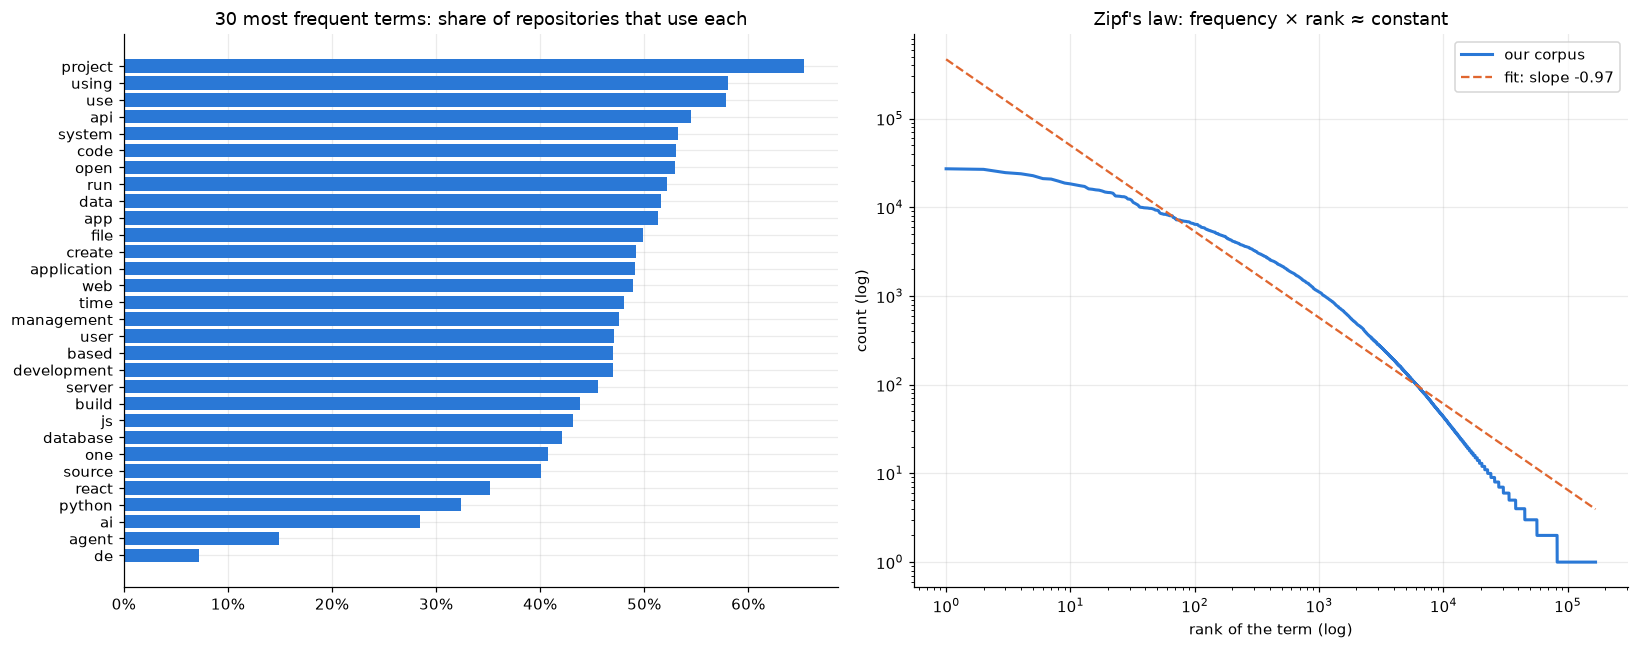

In [5]:
STOP = set(stopwords.words("english"))
TOKEN = re.compile(r"[a-z][a-z0-9]+")
docs = (corpus["description"].str.replace("not specified", "") + " " + corpus["readme"]).str.lower()
tf, df = Counter(), Counter()
for t in docs:
    toks = [x for x in TOKEN.findall(t) if x not in STOP]
    tf.update(toks)
    df.update(set(toks))
N = len(corpus)
top = pd.DataFrame(tf.most_common(30), columns=["term", "count"])
top["in % of repos"] = top["term"].map(lambda x: df[x] / N)
top = top.sort_values("in % of repos", ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
ax[0].barh(top["term"][::-1], top["in % of repos"][::-1], color=BLUE)
ax[0].xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax[0].set_title("30 most frequent terms: share of repositories that use each")
freq = np.array(sorted(tf.values(), reverse=True))
r = np.arange(1, len(freq) + 1)
ax[1].loglog(r, freq, color=BLUE, lw=2, label="our corpus")
idx = np.unique(np.logspace(1, 4.5, 60).astype(int)) - 1          # evenly spaced on the log axis, ranks 10 to ~30,000
slope, icpt = np.polyfit(np.log10(r[idx]), np.log10(freq[idx]), 1)
ax[1].loglog(r, 10 ** icpt * r ** slope, color=ORANGE, ls="--", lw=1.5, label=f"fit: slope {slope:.2f}")
ax[1].set_xlabel("rank of the term (log)")
ax[1].set_ylabel("count (log)")
ax[1].set_title("Zipf's law: frequency × rank ≈ constant")
ax[1].legend()
plt.tight_layout()
print(f"{sum(tf.values()):,} tokens | {len(tf):,} distinct terms | {sum(v == 1 for v in tf.values()):,} appear only once ({sum(v == 1 for v in tf.values()) / len(tf):.0%})")

In [6]:
# Candidate extra stop words: in a large share of repositories, but say nothing about what the project is.
common = pd.DataFrame([(t, df[t] / N) for t in df if df[t] / N >= 0.20], columns=["term", "share"]).sort_values("share", ascending=False)
print(", ".join(f"{t} {s:.0%}" for t, s in common.itertuples(index=False)))

project 65%, using 58%, use 58%, api 54%, system 53%, code 53%, open 53%, run 52%, data 52%, app 51%, features 50%, file 50%, create 49%, application 49%, web 49%, time 48%, management 48%, user 47%, based 47%, development 47%, built 47%, server 46%, build 44%, new 43%, js 43%, database 42%, full 42%, see 41%, add 41%, one 41%, repository 41%, real 40%, source 40%, support 40%, install 40%, github 39%, start 39%, like 39%, first 38%, stack 37%, get 36%, backend 35%, used 35%, react 35%, set 35%, license 35%, ui 35%, access 34%, platform 34%, tools 34%, key 33%, files 33%, design 33%, list 33%, via 33%, make 33%, local 33%, framework 33%, python 32%, node 32%, also 32%, work 32%, documentation 32%, without 31%, environment 31%, users 31%, free 31%, setup 31%, need 31%, version 30%, integration 30%, page 30%, available 30%, running 30%, library 30%, frontend 30%, search 29%, check 29%, browser 29%, live 29%, request 29%, service 29%, ai 28%, architecture 28%, simple 28%, security 28%, cl

**This shows** that Zipf's law holds in the middle and tail (a straight line on log–log; the head is flatter, as usual for real text), and that the most frequent terms are **README boilerplate**: *project* (65% of repositories), *using, use, run, code, open, file, create, install, github, license, clone, contributing* appear everywhere, whatever the project does. A few non-English words survive (*de* in 7% of repositories: bilingual READMEs passed the 5% stop-word rule). **So we will** add a short list of **README stop words** in Phase 6 (the install/contribute vocabulary), but **not** technology names or domain words even when they are common (*api, react, database, management* carry meaning for our queries). Half of the 167,548 distinct terms appear only once (typos, identifiers, names): we keep them, as they cost little and BM25's IDF gives them no weight unless a query asks for them.

## 5. Does the technology dictionary cover the corpus?

A **preview** of the Phase 6 extractor: match every alias in `config/technologies.yaml` (whole words) against the topics, the language list, the description and the README. We split the matches into **reliable** (found in topics or GitHub's language list) and **text only** (found only in the description or README).

no technology at all: 175 (2.1%) | only text matches: 19%


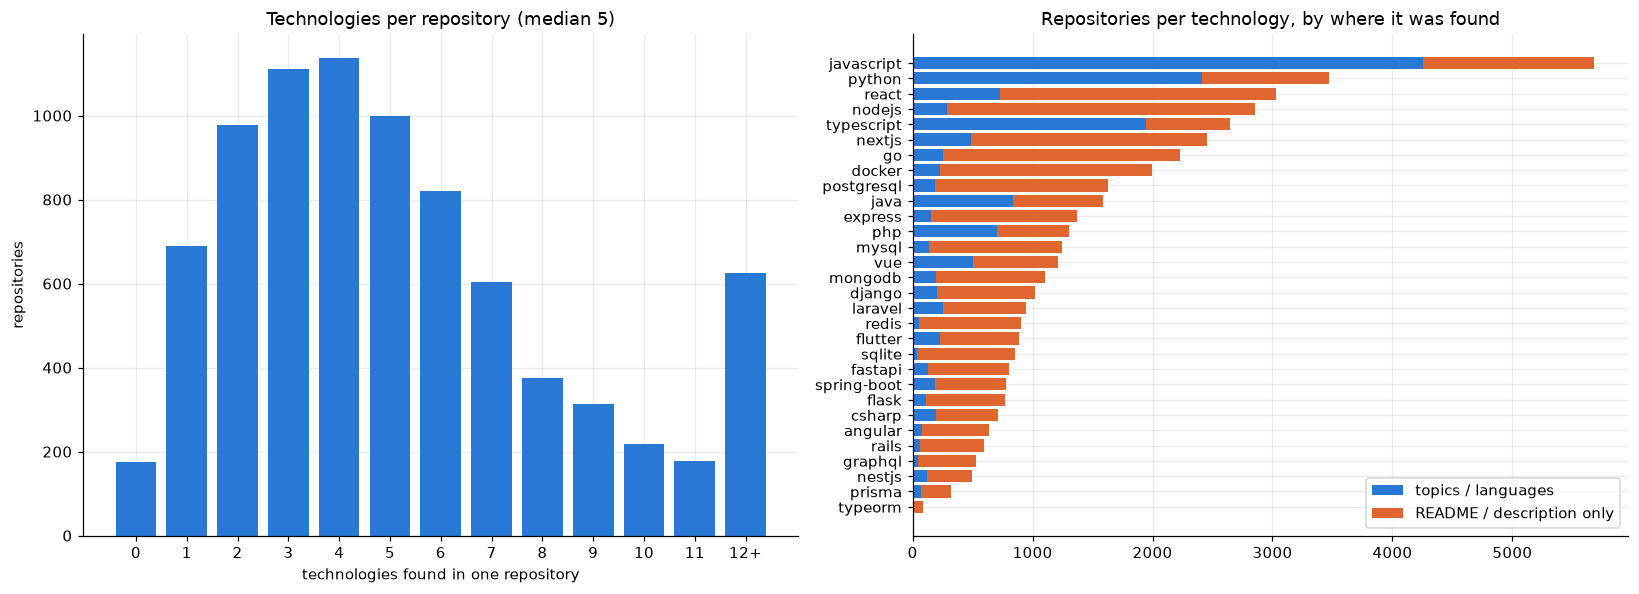

In [7]:
tech = yaml.safe_load(open(BACKEND / "config" / "technologies.yaml"))
alias_re = {canon: re.compile(r"(?<![a-z0-9])(?:" + "|".join(re.escape(a.lower()) for a in sorted(al, key=len, reverse=True)) + r")(?![a-z0-9])")
            for canon, al in tech.items()}


def find_tech(row):
    struct = " ".join(row.topics).lower().replace("-", " ") + " " + " ".join(row.topics).lower() + " " + " ".join(json.loads(row.languages)).lower()
    text = (row.description + " " + row.readme).lower()
    rel = {c for c, rx in alias_re.items() if rx.search(struct)}
    txt = {c for c, rx in alias_re.items() if c not in rel and rx.search(text)}
    return rel, txt


found = [find_tech(r) for r in corpus.itertuples()]
corpus["tech_reliable"] = [sorted(a) for a, _ in found]
corpus["tech_text"] = [sorted(b) for _, b in found]
n_tech = corpus["tech_reliable"].str.len() + corpus["tech_text"].str.len()

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
cnt = n_tech.clip(upper=12).value_counts().sort_index()
ax[0].bar(cnt.index, cnt.values, color=BLUE, width=.8)
ax[0].set_xticks(range(13), [str(i) for i in range(12)] + ["12+"])
ax[0].set_xlabel("technologies found in one repository")
ax[0].set_ylabel("repositories")
ax[0].set_title(f"Technologies per repository (median {n_tech.median():.0f})")
rel = Counter(c for cs in corpus["tech_reliable"] for c in cs)
txt = Counter(c for cs in corpus["tech_text"] for c in cs)
t = pd.DataFrame({"reliable": rel, "text only": txt}).fillna(0).astype(int)
t = t.loc[t.sum(axis=1).sort_values().index]
ax[1].barh(t.index, t["reliable"], color=BLUE, label="topics / languages")
ax[1].barh(t.index, t["text only"], left=t["reliable"], color=ORANGE, label="README / description only")
ax[1].legend(loc="lower right")
ax[1].set_title("Repositories per technology, by where it was found")
plt.tight_layout()
print(f"no technology at all: {(n_tech == 0).sum():,} ({(n_tech == 0).mean():.1%}) | only text matches: {((corpus['tech_reliable'].str.len() == 0) & (n_tech > 0)).mean():.0%}")

In [8]:
# Which aliases are risky? Compare with GitHub's own main language, where one exists.
check = {"go": "Go", "java": "Java", "php": "PHP", "python": "Python", "typescript": "TypeScript", "csharp": "C#"}
rows = []
for canon, lang in check.items():
    hit = corpus["tech_reliable"].map(lambda c: canon in c) | corpus["tech_text"].map(lambda c: canon in c)
    rows.append({"technology": canon, "matched": int(hit.sum()), f"main language agrees": f"{(corpus.loc[hit, 'language'] == lang).mean():.0%}",
                 "text-only share": f"{corpus['tech_text'].map(lambda c: canon in c)[hit].mean():.0%}"})
display(pd.DataFrame(rows))

# Topics people use that our dictionary doesn't know (new alias candidates)
known = {a.lower() for al in tech.values() for a in al} | set(tech)
generic = {"awesome", "awesome-list", "open-source", "opensource", "hacktoberfest", "api", "ai", "web", "app", "website",
           "portfolio", "ecommerce", "e-commerce", "blog", "chat", "todo", "todolist", "todo-app", "crm", "pos", "inventory",
           "inventory-management", "school-management", "hospital-management", "library-management", "booking", "frontend",
           "backend", "fullstack", "full-stack", "webapp", "web-app", "self-hosted", "list", "resources"}
unk = Counter(t for ts in corpus["topics"] for t in ts if t not in known and t not in generic and t.replace("-", " ") not in known)
print("frequent topics missing from technologies.yaml:", ", ".join(f"{t} ({n})" for t, n in unk.most_common(30)))

,technology,matched,main language agrees,text-only share
0,go,2232,4%,89%
1,java,1585,28%,47%
2,php,1302,29%,46%
3,python,3471,36%,30%
4,typescript,2642,49%,26%
5,csharp,713,14%,72%


frequent topics missing from technologies.yaml: tailwindcss (241), ai-agents (149), llm (142), css (121), android (115), mcp (114), html (110), dart (101), firebase (93), machine-learning (87), claude-code (86), python3 (83), rest-api (71), developer-tools (71), claude (69), ios (62), openai (58), html5 (58), bootstrap (57), github (57), point-of-sale (57), automation (55), redux (55), rag (54), shadcn-ui (54), linux (53), rust (53), django-rest-framework (49), ruby (48), css3 (48)


**This shows** that the dictionary finds a technology in **98%** of repositories (median 5), but with two problems: (1) **short, everyday aliases are unreliable in free text**: *go* matches 2,232 repositories, 89% from the README only, and only **4%** of them are actually written in Go ("go to the folder…"); *node*, *next*, *express*, *.net* behave the same way; (2) **common technologies are missing**: topics like *tailwindcss* (241), *css/html*, *android*, *dart*, *firebase*, *bootstrap*, *redux*, *ruby*, *rust*, *ios* appear dozens to hundreds of times. **So we will**, in Phase 6: add the missing technologies as new entries; for ambiguous aliases (*go, next, express, nest, rails, ts, js, pg, node, .net*), accept them **only from topics, the language list, or a qualified form** (*golang, next.js, express.js, nestjs, ruby on rails*); and keep the README match for unambiguous names (*django, laravel, postgresql …*).

## 6. Topics and contributors: what can the graph rely on?

Phase 12 links repositories that share a **contributor** or a **topic**. How many repositories would get at least one link?

linked by a shared contributor: 26% of repositories
linked by a shared topic (ignoring topics in > 2% of repos = 164): 49%
linked by either: 60%


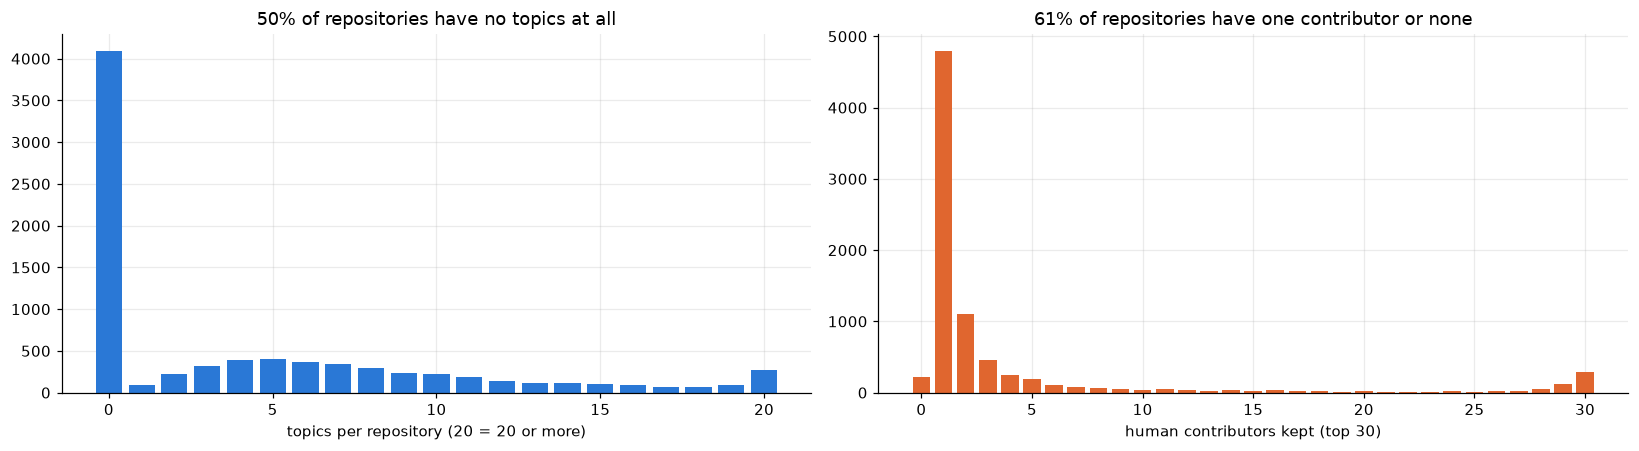

In [9]:
ntop = corpus["topics"].str.len()
ncon = corpus["contributors"].str.len()
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
c1 = ntop.clip(upper=20).value_counts().sort_index()
ax[0].bar(c1.index, c1.values, color=BLUE)
ax[0].set_xlabel("topics per repository (20 = 20 or more)")
ax[0].set_title(f"{(ntop == 0).mean():.0%} of repositories have no topics at all")
c2 = ncon.clip(upper=30).value_counts().sort_index()
ax[1].bar(c2.index, c2.values, color=ORANGE)
ax[1].set_xlabel("human contributors kept (top 30)")
ax[1].set_title(f"{(ncon <= 1).mean():.0%} of repositories have one contributor or none")
plt.tight_layout()


def linked(lists, max_size=None):
    """Share of repositories that share at least one item with another repository.
    Items in more than max_size repositories are ignored (a topic like 'react' links everything to everything)."""
    holders = {}
    for i, items in enumerate(lists):
        for x in set(items):
            holders.setdefault(x, []).append(i)
    hit = set()
    for x, ids in holders.items():
        if len(ids) > 1 and (max_size is None or len(ids) <= max_size):
            hit.update(ids)
    return len(hit) / len(lists)


lim = int(0.02 * N)
print(f"linked by a shared contributor: {linked(corpus['contributors']):.0%} of repositories")
print(f"linked by a shared topic (ignoring topics in > 2% of repos = {lim}): {linked(corpus['topics'], lim):.0%}")
print(f"linked by either: {linked([list(c) + ['#' + t for t in tp] for c, tp in zip(corpus['contributors'], corpus['topics'])]):.0%}")

**This shows** that half of the repositories have **no topics** and **61% have one contributor or none**. Shared contributors link only **26%** of repositories, shared topics **49%**, both together **60%**: 4 in 10 repositories would have no neighbour at all (PageRank gives them only the base score). **So we will** build the Phase 12 graph from **both** edge types together, drop over-common topics (more than 2% of repositories), and keep the popularity weight modest: for most repositories the graph says little, and relevance must do the work.

## 7. Extra: what is in the corpus that is not a project?

Sections 3 and 4 kept pointing at the same thing: **link lists** ("awesome …", curated lists, directories) and **GitHub profile repositories** (`user/user`, whose README is a personal page). They mention every framework and every domain, so a keyword search would rank them near the top for almost any query.

,repositories,median_stars,share_of_all_stars,median_pieces_found_in
kind,,,,
link list,814,54.0,61%,9.0
profile page,397,9.0,5%,3.0
project,7012,13.0,34%,1.0


,full_name,found_in,stars,links
18,2-fly-4-ai/awesome-shadcnui,70,564,1774
1799,Olivianik/awesome-selfhosted,70,6,2622
1539,MasterAffan/Hacktoberfest-25-Projects,66,55,413
2260,Siddhant-K-code/sponsorable-github-users-in-india,66,10,3729
4202,eric-erki/awesome-selfhosted,66,16,2024
3404,bikramtuladhar/awesome-list,64,12,1741
2655,Zaid-maker/my-awesome-stars-list,60,12,2196
3286,aw-junaid/self-hostable-services,60,17,2645


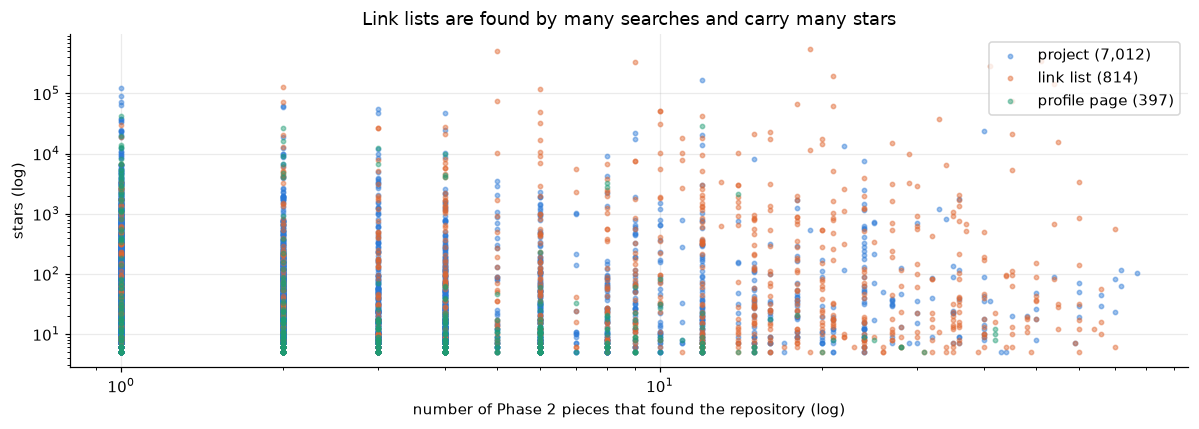

In [10]:
LINK = re.compile(r"\]\((?:https?://|\.?/)[^)]*\)|<a\s+href", re.I)
raw_links = {}
for r in iter_jsonl(PATHS["raw"] / "repos.jsonl"):
    t = r.get("readme") or ""
    raw_links[r["full_name"]] = (len(LINK.findall(t)), max(1, len(t.split())))
corpus["links"] = corpus["full_name"].map(lambda n: raw_links[n][0])
corpus["links_per_100w"] = corpus["full_name"].map(lambda n: 100 * raw_links[n][0] / raw_links[n][1])
says_list = (corpus["name"].str.contains("awesome", case=False)
             | corpus["description"].str.contains(r"\b(?:curated|awesome) list|\blist of\b|collection of (?:resources|links)", case=False))
corpus["is_list"] = ((corpus["links"] >= 50) & (corpus["links_per_100w"] >= 8)) | (says_list & (corpus["links"] >= 30))
corpus["is_profile"] = (corpus["owner"].str.lower() == corpus["name"].str.lower()) | (corpus["name"] == ".github")
corpus["found_in"] = corpus["found_by"].str.len()

kind = np.select([corpus["is_list"], corpus["is_profile"]], ["link list", "profile page"], "project")
summary = pd.DataFrame({"kind": kind, "stars": corpus["stars"], "found_in": corpus["found_in"]}).groupby("kind").agg(
    repositories=("stars", "size"), median_stars=("stars", "median"), share_of_all_stars=("stars", "sum"),
    median_pieces_found_in=("found_in", "median"))
summary["share_of_all_stars"] = (summary["share_of_all_stars"] / corpus["stars"].sum()).map("{:.0%}".format)
display(summary)

fig, ax = plt.subplots(figsize=(11, 4))
for k, col in [("project", BLUE), ("link list", ORANGE), ("profile page", GREEN)]:
    m = kind == k
    ax.scatter(corpus.loc[m, "found_in"], corpus.loc[m, "stars"], s=8, alpha=.45, color=col, label=f"{k} ({m.sum():,})")
ax.set_yscale("log")
ax.set_xscale("log")
ax.set_xlabel("number of Phase 2 pieces that found the repository (log)")
ax.set_ylabel("stars (log)")
ax.set_title("Link lists are found by many searches and carry many stars")
ax.legend()
plt.tight_layout()
corpus[corpus["is_list"]].nlargest(8, "found_in")[["full_name", "found_in", "stars", "links"]]

**This shows** **814 link lists (10%)** and **397 profile pages (5%)**. A typical link list was found by 9 of our searches (a real project: 1) and **link lists hold 61% of all stars** in the corpus, so they would rank well **both** on text (they name everything) **and** on popularity. **So we will** propose a 10th cleaning rule in Phase 4, **"not a software project"** (link lists and profile pages, using the two flags above), log how many it removes, and spot-check 20 of them by hand before applying it. *(Team decision; not applied yet. The flags are computed here so the numbers are ready.)*

## 8. Extra: age, activity and language

created in 2025–2026: 34% | pushed in the last 12 months: 46% | no main language: 16% | licence not specified: 50%


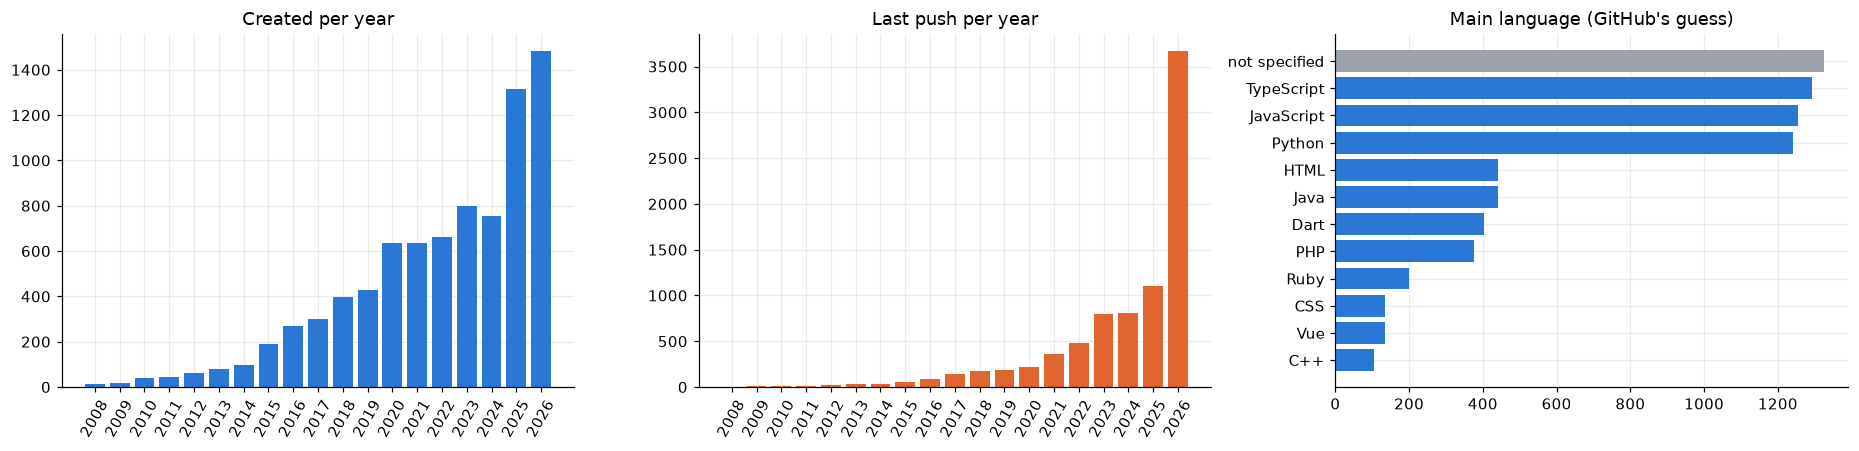

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
cy = corpus["created_at"].str[:4].value_counts().sort_index()
py = corpus["pushed_at"].str[:4].value_counts().sort_index()
ax[0].bar(cy.index, cy.values, color=BLUE)
ax[0].set_title("Created per year")
ax[1].bar(py.index, py.values, color=ORANGE)
ax[1].set_title("Last push per year")
for a in ax[:2]:
    a.tick_params(axis="x", rotation=60)
lang = corpus["language"].value_counts().head(12)[::-1]
ax[2].barh(lang.index, lang.values, color=[GREY if x == "not specified" else BLUE for x in lang.index])
ax[2].set_title("Main language (GitHub's guess)")
plt.tight_layout()
recent = (corpus["pushed_at"] >= "2025-11-23").mean()
print(f"created in 2025–2026: {(corpus['created_at'] >= '2025').mean():.0%} | pushed in the last 12 months: {recent:.0%} | "
      f"no main language: {(corpus['language'] == 'not specified').mean():.0%} | licence not specified: {(corpus['license'] == 'not specified').mean():.0%}")

**This shows** a young corpus: **34% were created in 2025–2026** and **46% were pushed in the last 12 months**, the rest are older and quieter. One in six (16%) has **no main language** (mostly the link lists and profile pages from section 7), and **half have no licence**. **So we will** show "last update" with every result and offer it as a filter (Phase 11), but not mix it into the score, and the app shows "licence: not specified" instead of hiding those repositories.

## What we found (for the report)

1. **Size and balance.** 8,657 fetched → **8,223 after cleaning** (434 removed: 23 empty, 411 not English). Below the 10,000 target because one repository matches many slices. Big domains ≈ 900 each; **point of sale 438, school 334, hospital 287**; 22 of 144 slices under 40. *Decision:* no re-crawl; avoid thin pairs in the test queries; report 8,223.
2. **Text.** Median README ≈ 520 words; **13% under 100 words**; 16% hit the 20,000-character cap. *Decision:* keep the cap; semantic search should matter most for short READMEs (testable in Phase 14).
3. **Popularity is a power law** (top 1% hold 76% of stars), and the most-starred repositories are link lists. *Decision:* log-scale stars, keep the popularity weight small.
4. **Vocabulary follows Zipf** (167,548 distinct terms, half used once); the top terms are README boilerplate (project 65%, use, run, install …). *Decision:* add README stop words in Phase 6, keep technology and domain words.
5. **Technologies:** the dictionary misses common names (tailwindcss, firebase, android, kotlin …) and short aliases are unreliable in free text (*go*: 2,232 matches, only 4% really Go). *Decision:* extend `technologies.yaml`; accept ambiguous aliases only from topics/languages.
6. **Graph:** half the repositories have no topics, 61% have ≤ 1 contributor; both edge types together link only 60%. *Decision:* combine contributor and topic edges; drop topics in > 2% of repositories.
7. **Not projects:** 814 link lists and 397 profile pages (15%); the lists hold 61% of all stars. *Decision (team):* add a "not a software project" cleaning rule after a hand check.

| Phase | Change it causes |
|---|---|
| 4 Clean | Optional rule 10: drop link lists and profile pages (flags in section 7) |
| 6 Text | README stop words; new technologies; ambiguous aliases only from topics/languages |
| 11 Filters | "last update" as a filter, not a score |
| 12 Popularity | `log1p(stars)`; contributor + topic edges; ignore topics in > 2% of repos |
| 13 Queries | Keep school/hospital queries, avoid thin pairs (e.g. hospital + NestJS: 8) |
| 14 Evaluate | Compare methods on short vs long READMEs (semantic should help on short ones) |